# CNN para Classificação de Doenças em Cana-de-Açúcar — ESP32-S3 (v03 Otimizado)

**Objetivo:** Extrair o máximo desempenho pós-quantização (Int8) comparando duas arquiteturas (CNN Customizada vs MobileNetV2 $\alpha=0.35$) para embarcar no microcontrolador ESP32-S3.

**Hardware alvo:** ESP32-S3 N8R16 (8MB PSRAM, 512KB SRAM) com aceleração vetorial SIMD (`esp-nn`).

---

## 🛠️ Otimizações e Correções Aplicadas nesta Versão (v03)

1. **Correção do Cache no Data Augmentation:** `.cache()` agora é executado **antes** do `data_augmentation`. Isso garante que novas distorções aleatórias sejam geradas a cada época em tempo real na GPU, evitando que o modelo decore imagens estáticas.
2. **Zero Overhead Float32 no TFLite (Input em `[-1, 1]` fora do modelo):** As camadas `Rescaling` e `preprocess_input` foram movidas para o pipeline `tf.data`. Assim, o grafo `.tflite` exportado começa direto na primeira camada convolucional Int8, eliminando nós `DEQUANTIZE`/`QUANTIZE` ocultos na entrada e economizando ~307 KB de *Tensor Arena* (RAM) no ESP32-S3.
3. **BatchNorm Folding Garantido na CNN Customizada:** As camadas convolucionais foram reestruturadas no padrão `Conv2D(use_bias=False, activation=None)` $\rightarrow$ `BatchNormalization()` $\rightarrow$ `ReLU()`. Isso permite que o TFMOT e o TFLite fundam 100% dos BatchNorms nos pesos das convoluções.
4. **QAT Verdadeiro Desbloqueado no MobileNetV2:** A arquitetura foi construída com grafo *flat* (`input_tensor=inputs`), eliminando o sub-modelo aninhado e permitindo rodar *Quantization-Aware Training (QAT)* completo também no MobileNetV2.
5. **Correção de Desbalanceamento e Visualização Padronizada:** Adicionado `class_weight` suavizado + `label_smoothing=0.05` para proteger classes minoritárias (ex: *Pokkah Boeng*, *BrownRust*), e gráficos padronizados com Matrizes de Confusão Normalizadas (`0-100%`) e curvas de aprendizado.

## 0. Instalação e Imports

In [ ]:
!pip install kagglehub tensorflow-model-optimization --quiet

In [ ]:
# Célula de imports — forçar uso consistente do tf.keras (Legacy Keras para compatibilidade com TFMOT)
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import time
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

# Tudo via tf.keras — evita conflito com keras 3 standalone
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import confusion_matrix, classification_report, f1_score
from sklearn.utils.class_weight import compute_class_weight
import tensorflow_model_optimization as tfmot

# Configuração de sementes para reprodutibilidade
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

print(f"TensorFlow: {tf.__version__}")
print(f"GPU disponível: {len(tf.config.list_physical_devices('GPU')) > 0}")

TensorFlow: 2.21.0
GPU disponível: True


## 1. Preparação do Dataset no Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

IMG_EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

# Caminho da pasta do dataset dentro do seu Google Drive
CAMINHO_DATASET_ORIGEM = "/content/drive/MyDrive/tcc/datasets/Sugarcane leaf image dataset"
caminho_dataset = "/content/sugarcane_flat"

def tem_imagens_diretas(pasta):
    """True se a pasta tem arquivos de imagem direto nela (não em subpastas)."""
    try:
        return any(
            f.lower().endswith(IMG_EXTS) and os.path.isfile(os.path.join(pasta, f))
            for f in os.listdir(pasta)
        )
    except (FileNotFoundError, NotADirectoryError):
        return False

def descobrir_classes(raiz):
    classes = {}
    for item in sorted(os.listdir(raiz)):
        caminho_item = os.path.join(raiz, item)
        if not os.path.isdir(caminho_item):
            continue
        if tem_imagens_diretas(caminho_item):
            classes[item] = caminho_item
        else:
            for sub in sorted(os.listdir(caminho_item)):
                caminho_sub = os.path.join(caminho_item, sub)
                if os.path.isdir(caminho_sub) and tem_imagens_diretas(caminho_sub):
                    classes[sub] = caminho_sub
    return classes

def construir_dataset_flat(raiz_origem, raiz_destino, modo="symlink"):
    if not os.path.isdir(raiz_origem):
        raise FileNotFoundError(f"Pasta de origem não encontrada: {raiz_origem}")

    classes = descobrir_classes(raiz_origem)
    if not classes:
        raise RuntimeError(f"Nenhuma classe encontrada em: {raiz_origem}")

    os.makedirs(raiz_destino, exist_ok=True)

    print(f"Classes detectadas ({len(classes)}):")
    for nome_classe, caminho_origem in classes.items():
        imgs = [f for f in os.listdir(caminho_origem) if f.lower().endswith(IMG_EXTS)]
        print(f"  - {nome_classe:<18}: {len(imgs)} imagens")

        destino_classe = os.path.join(raiz_destino, nome_classe)
        os.makedirs(destino_classe, exist_ok=True)

        for f in imgs:
            src = os.path.join(caminho_origem, f)
            dst = os.path.join(destino_classe, f)
            if os.path.exists(dst):
                continue
            if modo == "symlink":
                os.symlink(os.path.abspath(src), dst)
            else:
                shutil.copy2(src, dst)

    print(f"\n✅ Dataset flat pronto em: {raiz_destino}")
    return raiz_destino

construir_dataset_flat(CAMINHO_DATASET_ORIGEM, caminho_dataset, modo="symlink")

Mounted at /content/drive
Classes detectadas (11):
  - Banded Chlorosis  : 471 imagens
  - Brown Spot        : 1722 imagens
  - BrownRust         : 314 imagens
  - Grassy shoot      : 346 imagens
  - Pokkah Boeng      : 297 imagens
  - Sett Rot          : 652 imagens
  - Viral Disease     : 663 imagens
  - Yellow Leaf       : 1194 imagens
  - smut              : 316 imagens
  - Dried Leaves      : 343 imagens
  - Healthy Leaves    : 430 imagens

✅ Dataset flat pronto em: /content/sugarcane_flat


'/content/sugarcane_flat'

## 2. Carregamento, Class Weights e Pipeline de Dados Otimizado para Int8

> **Por que normalizar para `[-1.0, 1.0]` no pipeline e não dentro do modelo?**
> - Quando camadas como `Rescaling` ou `TFOpLambda` ficam dentro do modelo, o conversor TFLite insere operações `DEQUANTIZE` e `QUANTIZE` em `float32` na entrada do grafo, gastando ~307 KB extras de RAM (*Tensor Arena*) no ESP32-S3.
> - Normalizando para `[-1.0, 1.0]` no pipeline (`(pixel - 127.5) / 127.5`), o modelo TFLite fica **100% Int8 puro** do início ao fim (`scale ≈ 0.007843`, `zero_point = 0` ou `-1`).
> - No código C/C++ do ESP32-S3, converter um byte da câmera (`uint8_t` em `[0, 255]`) para a entrada do modelo (`int8_t` em `[-128, 127]`) resume-se a uma única subtração inteira instantânea: `int8_t in = (int8_t)(pixel_u8 - 128);`.

In [ ]:
BATCH_SIZE = 32
IMG_SIZE = (160, 160)
IMG_SHAPE = (160, 160, 3)
AUTOTUNE = tf.data.AUTOTUNE

# 1. Carrega os datasets brutos em [0, 255]
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    caminho_dataset,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

#Print das classes de forma ordenada
print("\n-------------Classes-------------")
print(train_ds_raw.class_names)

val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    caminho_dataset,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

class_names = train_ds_raw.class_names
NUM_CLASSES = len(class_names)
print(f"\nClasses ({NUM_CLASSES}): {class_names}")

# 2. ✅ OTIMIZAÇÃO: Conta imagens direto nas pastas sem decodificar pixels via Drive
IMG_EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
class_counts = []
for nome in class_names:
    pasta = os.path.join(caminho_dataset, nome)
    qtd_total = len([f for f in os.listdir(pasta) if f.lower().endswith(IMG_EXTS)])
    # 80% do split de treino
    qtd_treino = int(qtd_total * 0.8)
    class_counts.append(qtd_treino)

total_amostras = sum(class_counts)
# Fórmula balanceada: total / (n_classes * count)
pesos_brutos = [total_amostras / (NUM_CLASSES * c) for c in class_counts]
class_weights_dict = {i: float(np.sqrt(p)) for i, p in enumerate(pesos_brutos)}

print("\nPesos de classe aplicados (calculados instantaneamente):")
for i, nome in enumerate(class_names):
    print(f"  - {nome:<18}: ~{class_counts[i]:>4} imgs de treino | peso = {class_weights_dict[i]:.2f}")

# 3. Data Augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="data_augmentation")

# ✅ Sintaxe corrigida em linha única
def normalizar_padrao_int8(img, label):
    """Converte float32 [0.0, 255.0] para [-1.0, 1.0]."""
    img = (tf.cast(img, tf.float32) / 127.5) - 1.0
    return img, label

# Pipelines com .cache() antes do aumento
train_ds_aug = (
    train_ds_raw
    .cache()
    .shuffle(1000, seed=SEED)
    .map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
    .map(normalizar_padrao_int8, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

val_ds_norm = (
    val_ds_raw
    .map(normalizar_padrao_int8, num_parallel_calls=AUTOTUNE)
    .cache()
    .prefetch(AUTOTUNE)
)

# Teste rápido do primeiro batch
for imgs, lbls in val_ds_norm.take(1):
    print(f"\n✅ Pipelines prontos! Range: [{imgs.numpy().min():.2f}, {imgs.numpy().max():.2f}] | Shape: {imgs.shape}")

Found 6748 files belonging to 11 classes.
Using 5399 files for training.

-------------Classes-------------
['Banded Chlorosis', 'Brown Spot', 'BrownRust', 'Dried Leaves', 'Grassy shoot', 'Healthy Leaves', 'Pokkah Boeng', 'Sett Rot', 'Viral Disease', 'Yellow Leaf', 'smut']
Found 6748 files belonging to 11 classes.
Using 1349 files for validation.

Classes (11): ['Banded Chlorosis', 'Brown Spot', 'BrownRust', 'Dried Leaves', 'Grassy shoot', 'Healthy Leaves', 'Pokkah Boeng', 'Sett Rot', 'Viral Disease', 'Yellow Leaf', 'smut']

Pesos de classe aplicados (calculados instantaneamente):
  - Banded Chlorosis  : ~ 376 imgs de treino | peso = 1.14
  - Brown Spot        : ~1377 imgs de treino | peso = 0.60
  - BrownRust         : ~ 251 imgs de treino | peso = 1.40
  - Dried Leaves      : ~ 274 imgs de treino | peso = 1.34
  - Grassy shoot      : ~ 276 imgs de treino | peso = 1.33
  - Healthy Leaves    : ~ 344 imgs de treino | peso = 1.19
  - Pokkah Boeng      : ~ 237 imgs de treino | peso = 1.44

---
# MODELO A — CNN Customizada (Otimizada para *BatchNorm Folding*)

**Melhorias de arquitetura para o ESP32-S3:**
- Padrão `Conv2D(use_bias=False)` $\rightarrow$ `BatchNormalization()` $\rightarrow$ `ReLU()`: garante que o TFMOT e o TFLite fundam os parâmetros do BatchNorm dentro dos pesos da convolução (*Folding*), eliminando camadas extras de multiplicação/soma em tempo de inferência.
- `GlobalAveragePooling2D` + Head enxuto.
- `Label Smoothing (0.05)` + `Class Weights` para melhorar a generalização e evitar logits saturados que prejudicam a quantização Int8.

In [ ]:
def build_cnn_customizada(num_classes):
    model = tf.keras.Sequential([
        layers.Input(shape=IMG_SHAPE, name="input_image"),

        # Bloco 1
        layers.Conv2D(32, (3,3), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.Conv2D(64, (3,3), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.2),

        # Bloco 2
        layers.Conv2D(64, (3,3), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.Conv2D(128, (3,3), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.25),

        # Bloco 3
        layers.Conv2D(128, (3,3), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.Conv2D(256, (3,3), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.3),

        # Bloco 4
        layers.Conv2D(256, (3,3), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.3),

        # Classificador (Head)
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, use_bias=False),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.Dropout(0.4),
        layers.Dense(num_classes, activation='softmax', name="predictions")
    ], name="cnn_customizada")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
        metrics=['accuracy']
    )
    return model

model_cnn = build_cnn_customizada(NUM_CLASSES)
model_cnn.summary()

Model: "cnn_customizada"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_14 (Conv2D)          (None, 160, 160, 32)      864       
                                                                 
 batch_normalization_16 (Ba  (None, 160, 160, 32)      128       
 tchNormalization)                                               
                                                                 
 re_lu_16 (ReLU)             (None, 160, 160, 32)      0         
                                                                 
 conv2d_15 (Conv2D)          (None, 160, 160, 64)      18432     
                                                                 
 batch_normalization_17 (Ba  (None, 160, 160, 64)      256       
 tchNormalization)                                               
                                                                 
 re_lu_17 (ReLU)             (None, 160, 160, 64)  

In [ ]:
callbacks_cnn = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=1, cooldown=1
    )
]

print("Treinando CNN Customizada (Float32)...")
history_cnn = model_cnn.fit(
    train_ds_aug,
    epochs=75,
    validation_data=val_ds_norm,
    class_weight=class_weights_dict,
    callbacks=callbacks_cnn
)

val_loss_cnn, val_acc_cnn = model_cnn.evaluate(val_ds_norm, verbose=0)
print(f"\n✅ Treinamento Float32 concluído! Acurácia Float32: {val_acc_cnn*100:.2f}%")

Treinando CNN Customizada (Float32)...
Epoch 1/75
169/169 [==============================] - 75s 250ms/step - loss: 1.6541 - accuracy: 0.4684 - val_loss: 3.0191 - val_accuracy: 0.1898 - lr: 0.0010
Epoch 2/75
169/169 [==============================] - 38s 223ms/step - loss: 1.3096 - accuracy: 0.5862 - val_loss: 1.7720 - val_accuracy: 0.3966 - lr: 0.0010
Epoch 3/75
169/169 [==============================] - 39s 231ms/step - loss: 1.1872 - accuracy: 0.6329 - val_loss: 1.8303 - val_accuracy: 0.5589 - lr: 0.0010
Epoch 4/75
169/169 [==============================] - 38s 226ms/step - loss: 1.1164 - accuracy: 0.6523 - val_loss: 1.5072 - val_accuracy: 0.5597 - lr: 0.0010
Epoch 5/75
169/169 [==============================] - 39s 227ms/step - loss: 1.0457 - accuracy: 0.6809 - val_loss: 4.3796 - val_accuracy: 0.3254 - lr: 0.0010
Epoch 6/75
169/169 [==============================] - 38s 226ms/step - loss: 1.0172 - accuracy: 0.6985 - val_loss: 1.4809 - val_accuracy: 0.5545 - lr: 0.0010
Epoch 7/75
16

### QAT (Quantization-Aware Training) — Modelo A (CNN Customizada)

> Como o modelo agora possui apenas camadas nativas suportadas (`Conv2D`, `BatchNormalization`, `ReLU`, `MaxPooling2D`, `GlobalAveragePooling2D`, `Dense`), o `tfmot.quantization.keras.quantize_model` funciona diretamente sem precisar de anotações customizadas.

In [ ]:
print("Aplicando QAT na CNN Customizada...")
model_cnn_qat = tfmot.quantization.keras.quantize_model(model_cnn)

model_cnn_qat.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-5),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    metrics=['accuracy']
)

callbacks_qat_cnn = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=6, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1
    )
]

history_cnn_qat = model_cnn_qat.fit(
    train_ds_aug,
    epochs=20,
    validation_data=val_ds_norm,
    class_weight=class_weights_dict,
    callbacks=callbacks_qat_cnn
)

val_loss_qat_a, val_acc_qat_a = model_cnn_qat.evaluate(val_ds_norm, verbose=0)
print(f"\n✅ QAT CNN concluído! Acurácia pós-QAT (simulada): {val_acc_qat_a*100:.2f}%")

Aplicando QAT na CNN Customizada...
Epoch 1/20
169/169 [==============================] - 53s 279ms/step - loss: 0.4846 - accuracy: 0.9313 - val_loss: 0.6756 - val_accuracy: 0.8547 - lr: 5.0000e-05
Epoch 2/20
169/169 [==============================] - 47s 275ms/step - loss: 0.4828 - accuracy: 0.9374 - val_loss: 0.7795 - val_accuracy: 0.8169 - lr: 5.0000e-05
Epoch 3/20
169/169 [==============================] - 47s 276ms/step - loss: 0.4795 - accuracy: 0.9355 - val_loss: 0.7263 - val_accuracy: 0.8317 - lr: 5.0000e-05
Epoch 4/20
169/169 [==============================] - ETA: 0s - loss: 0.4830 - accuracy: 0.9350
Epoch 4: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
169/169 [==============================] - 47s 275ms/step - loss: 0.4830 - accuracy: 0.9350 - val_loss: 0.7278 - val_accuracy: 0.8302 - lr: 5.0000e-05
Epoch 5/20
169/169 [==============================] - 47s 276ms/step - loss: 0.4774 - accuracy: 0.9376 - val_loss: 0.7381 - val_accuracy: 0.8340 - lr: 2.50

---
# MODELO B — MobileNetV2 ($\alpha=0.35$) com Grafo Flat e QAT Completo

**Por que esta construção extrai o máximo do ESP32-S3?**
- Ao instanciar `MobileNetV2(input_tensor=inputs, ...)`, o Keras constrói um **grafo flat único** em vez de aninhar um objeto `Functional` dentro de outro. Isso desbloqueia o `tfmot.quantize_model` para rodar **QAT verdadeiro** no MobileNetV2!
- As convoluções separáveis em profundidade (*Depthwise Separable Convolutions*) do MobileNetV2 contam com kernels em Assembly SIMD dedicados na biblioteca `esp-nn` da Espressif, executando muito mais rápido e usando metade da memória Flash/RAM que a CNN Customizada.

In [ ]:
def build_mobilenetv2_flat(num_classes, alpha=0.35):
    inputs = keras.Input(shape=IMG_SHAPE, name="input_image")

    # Passar input_tensor=inputs evita criar um sub-modelo aninhado e habilita QAT direto!
    base_model = keras.applications.MobileNetV2(
        input_tensor=inputs,
        alpha=alpha,
        include_top=False,
        weights='imagenet'
    )

    # Fase 1: Congela os pesos do extrator de características pré-treinado
    for layer in base_model.layers:
        layer.trainable = False

    x = base_model.output
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.35, name="top_dropout")(x)
    outputs = layers.Dense(num_classes, activation='softmax', name="predictions")(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name=f"mobilenetv2_a{alpha}")
    return model

model_mbnet = build_mobilenetv2_flat(NUM_CLASSES, alpha=0.35)
model_mbnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    metrics=['accuracy']
)
model_mbnet.summary()

Model: "mobilenetv2_a0.35"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_image (InputLayer)    [(None, 160, 160, 3)]        0         []                            
                                                                                                  
 Conv1 (Conv2D)              (None, 80, 80, 16)           432       ['input_image[0][0]']         
                                                                                                  
 bn_Conv1 (BatchNormalizati  (None, 80, 80, 16)           64        ['Conv1[0][0]']               
 on)                                                                                              
                                                                                                  
 Conv1_relu (ReLU)           (None, 80, 80, 16)           0         ['bn_Conv1[0][

In [ ]:
# --- Fase 1: Treinar apenas o Head (base congelada) ---
print("FASE 1: Treinando head do MobileNetV2 com base congelada...")
history_mbnet_phase1 = model_mbnet.fit(
    train_ds_aug,
    epochs=15,
    validation_data=val_ds_norm,
    class_weight=class_weights_dict,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
    ]
)

# --- Fase 2: Fine-tuning completo (base descongelada) ---
print("\nFASE 2: Fine-tuning completo do MobileNetV2 (Float32)...")
for layer in model_mbnet.layers:
    layer.trainable = True

model_mbnet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-5),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    metrics=['accuracy']
)

history_mbnet_phase2 = model_mbnet.fit(
    train_ds_aug,
    epochs=50,
    validation_data=val_ds_norm,
    class_weight=class_weights_dict,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6, verbose=1)
    ]
)

val_loss_mb, val_acc_mb = model_mbnet.evaluate(val_ds_norm, verbose=0)
print(f"\n✅ Treinamento MobileNetV2 Float32 concluído! Acurácia Float32: {val_acc_mb*100:.2f}%")

FASE 1: Treinando head do MobileNetV2 com base congelada...
Epoch 1/15
169/169 [==============================] - 26s 135ms/step - loss: 1.5170 - accuracy: 0.5132 - val_loss: 1.1495 - val_accuracy: 0.6553
Epoch 2/15
169/169 [==============================] - 22s 128ms/step - loss: 1.1332 - accuracy: 0.6386 - val_loss: 1.0938 - val_accuracy: 0.6686
Epoch 3/15
169/169 [==============================] - 22s 130ms/step - loss: 1.0345 - accuracy: 0.6894 - val_loss: 1.0103 - val_accuracy: 0.7079
Epoch 4/15
169/169 [==============================] - 22s 128ms/step - loss: 0.9709 - accuracy: 0.7114 - val_loss: 0.9820 - val_accuracy: 0.7198
Epoch 5/15
169/169 [==============================] - 22s 130ms/step - loss: 0.9312 - accuracy: 0.7318 - val_loss: 0.9617 - val_accuracy: 0.7346
Epoch 6/15
169/169 [==============================] - 22s 128ms/step - loss: 0.9153 - accuracy: 0.7403 - val_loss: 0.9625 - val_accuracy: 0.7294
Epoch 7/15
169/169 [==============================] - 22s 129ms/step -

### QAT (Quantization-Aware Training) — Modelo B (MobileNetV2)

> Com o grafo flat, aplicamos QAT diretamente no MobileNetV2 para calibrar os pesos e ranges de ativação das camadas `DepthwiseConv2D` e `Conv2D` antes da exportação para Int8.

In [ ]:
print("FASE 3: Aplicando QAT (Quantization-Aware Training) no MobileNetV2...")
model_mbnet_qat = tfmot.quantization.keras.quantize_model(model_mbnet)

model_mbnet_qat.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    metrics=['accuracy']
)

callbacks_qat_mb = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=6, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1
    )
]

history_mbnet_qat = model_mbnet_qat.fit(
    train_ds_aug,
    epochs=15,
    validation_data=val_ds_norm,
    class_weight=class_weights_dict,
    callbacks=callbacks_qat_mb
)

val_loss_qat_b, val_acc_qat_b = model_mbnet_qat.evaluate(val_ds_norm, verbose=0)
print(f"\n✅ QAT MobileNetV2 concluído! Acurácia pós-QAT (simulada): {val_acc_qat_b*100:.2f}%")

FASE 3: Aplicando QAT (Quantization-Aware Training) no MobileNetV2...
Epoch 1/15
169/169 [==============================] - 66s 221ms/step - loss: 1.8243 - accuracy: 0.5142 - val_loss: 2.8440 - val_accuracy: 0.2031 - lr: 1.0000e-05
Epoch 2/15
169/169 [==============================] - 36s 214ms/step - loss: 1.0933 - accuracy: 0.7018 - val_loss: 1.7333 - val_accuracy: 0.5152 - lr: 1.0000e-05
Epoch 3/15
169/169 [==============================] - 36s 214ms/step - loss: 0.7534 - accuracy: 0.8124 - val_loss: 0.9313 - val_accuracy: 0.7606 - lr: 1.0000e-05
Epoch 4/15
169/169 [==============================] - 36s 211ms/step - loss: 0.5841 - accuracy: 0.8855 - val_loss: 0.7032 - val_accuracy: 0.8525 - lr: 1.0000e-05
Epoch 5/15
169/169 [==============================] - 36s 211ms/step - loss: 0.5108 - accuracy: 0.9205 - val_loss: 0.6759 - val_accuracy: 0.8599 - lr: 1.0000e-05
Epoch 6/15
169/169 [==============================] - 37s 215ms/step - loss: 0.4729 - accuracy: 0.9357 - val_loss: 0.658

---
# 3. Conversão TFLite Full Integer (Int8 Puro) — Modelo A e Modelo B

> Ambos os modelos recebem tensores em `[-1.0, 1.0]` e são convertidos com `TFLITE_BUILTINS_INT8` usando todo o conjunto de validação como dataset representativo.

In [ ]:
def representative_data_gen():
    """Gera amostras reais em [-1.0, 1.0] percorrendo todo o dataset de validação."""
    for images, _ in val_ds_norm:
        imgs_np = images.numpy()
        for i in range(len(imgs_np)):
            yield [np.expand_dims(imgs_np[i], axis=0).astype(np.float32)]

def converter_para_tflite_int8(keras_model, output_path):
    print(f"Convertendo {keras_model.name} para {output_path}...")
    converter = tf.lite.TFLiteConverter.from_keras_model(keras_model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_data_gen
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type = tf.int8
    converter.inference_output_type = tf.int8

    tflite_model = converter.convert()
    with open(output_path, "wb") as f:
        f.write(tflite_model)

    kb_size = os.path.getsize(output_path) / 1024
    print(f"✅ Conversão concluída! Tamanho: {kb_size:.2f} KB ({kb_size/1024:.2f} MB)\n")
    return kb_size

tamanho_cnn_kb = converter_para_tflite_int8(model_cnn_qat, "model_cnn_int8.tflite")
tamanho_mbnet_kb = converter_para_tflite_int8(model_mbnet_qat, "model_mbnet_int8.tflite")

Convertendo cnn_customizada para model_cnn_int8.tflite...


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


✅ Conversão concluída! Tamanho: 1205.95 KB (1.18 MB)

Convertendo mobilenetv2_a0.35 para model_mbnet_int8.tflite...


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


✅ Conversão concluída! Tamanho: 624.29 KB (0.61 MB)



---
# 4. Avaliação Comparativa e Verificação de Grafo Int8

In [ ]:
def avaliar_keras(model, val_dataset, desc="Modelo Float32"):
    predicoes, gabarito = [], []
    for images, labels in val_dataset:
        preds = model.predict(images, verbose=0)
        predicoes.extend(np.argmax(preds, axis=1))
        gabarito.extend(np.argmax(labels.numpy(), axis=1))

    predicoes = np.array(predicoes)
    gabarito = np.array(gabarito)

    cm = confusion_matrix(gabarito, predicoes)
    acuracias_por_classe = (cm.diagonal() / cm.sum(axis=1)) * 100
    acuracia_global = np.mean(predicoes == gabarito) * 100
    f1_macro = f1_score(gabarito, predicoes, average='macro') * 100

    print(f"✅ {desc:<26} | Acc Global: {acuracia_global:.2f}% | F1-Macro: {f1_macro:.2f}%")
    return cm, acuracias_por_classe, acuracia_global, f1_macro

def avaliar_tflite(model_path, val_dataset, desc="Modelo Int8"):
    interpreter = tf.lite.Interpreter(model_path=model_path)
    interpreter.allocate_tensors()

    input_details = interpreter.get_input_details()[0]
    output_details = interpreter.get_output_details()[0]

    in_scale, in_zp = input_details['quantization']
    out_scale, out_zp = output_details['quantization']

    # Verifica se há operações DEQUANTIZE ocultas no grafo
    ops = [op['op_name'] for op in interpreter._get_ops_details()]
    tem_float_op = any(op in ('DEQUANTIZE', 'QUANTIZE', 'MUL', 'SUB') for op in ops)

    predicoes, gabarito = [], []
    t0 = time.perf_counter()

    for images, labels in val_dataset:
        imgs_np = images.numpy()
        lbls_np = labels.numpy()
        for i in range(len(imgs_np)):
            # Quantiza de [-1.0, 1.0] float32 para [-128, 127] int8
            img_int8 = np.round(imgs_np[i] / in_scale + in_zp).clip(-128, 127).astype(np.int8)
            interpreter.set_tensor(input_details['index'], np.expand_dims(img_int8, axis=0))
            interpreter.invoke()
            output = interpreter.get_tensor(output_details['index'])[0]
            predicoes.append(np.argmax(output))
            gabarito.append(np.argmax(lbls_np[i]))

    latencia_ms = ((time.perf_counter() - t0) / len(predicoes)) * 1000
    predicoes = np.array(predicoes)
    gabarito = np.array(gabarito)

    cm = confusion_matrix(gabarito, predicoes)
    acuracias_por_classe = (cm.diagonal() / cm.sum(axis=1)) * 100
    acuracia_global = np.mean(predicoes == gabarito) * 100
    f1_macro = f1_score(gabarito, predicoes, average='macro') * 100

    print(f"✅ {desc:<26} | Acc Global: {acuracia_global:.2f}% | F1-Macro: {f1_macro:.2f}% | Scale: {in_scale:.6f}, ZP: {in_zp} | Latência Host: {latencia_ms:.2f} ms")
    print(f"   Operadores no grafo TFLite: {set(ops)} (100% Int8 Puro: {not tem_float_op})")
    return cm, acuracias_por_classe, acuracia_global, f1_macro, (in_scale, in_zp, out_scale, out_zp)

print("=" * 100)
print("RESULTADOS DA AVALIAÇÃO PADRONIZADA")
print("=" * 100)
cm_cnn_f32, acc_cnn_f32, global_cnn_f32, f1_cnn_f32 = avaliar_keras(model_cnn, val_ds_norm, "CNN Custom Float32")
cm_cnn_int8, acc_cnn_int8, global_cnn_int8, f1_cnn_int8, q_cnn = avaliar_tflite("model_cnn_int8.tflite", val_ds_norm, "CNN Custom Int8 (QAT)")
print("-" * 100)
cm_mb_f32, acc_mb_f32, global_mb_f32, f1_mb_f32 = avaliar_keras(model_mbnet, val_ds_norm, "MobileNetV2 Float32")
cm_mb_int8, acc_mb_int8, global_mb_int8, f1_mb_int8, q_mb = avaliar_tflite("model_mbnet_int8.tflite", val_ds_norm, "MobileNetV2 Int8 (QAT)")
print("=" * 100)

RESULTADOS DA AVALIAÇÃO PADRONIZADA
✅ CNN Custom Float32         | Acc Global: 85.32% | F1-Macro: 81.45%


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


✅ CNN Custom Int8 (QAT)      | Acc Global: 44.11% | F1-Macro: 25.05% | Scale: 0.007843, ZP: 0 | Latência Host: 63.64 ms
   Operadores no grafo TFLite: {'SOFTMAX', 'CONV_2D', 'FULLY_CONNECTED', 'MAX_POOL_2D', 'MEAN', 'DELEGATE'} (100% Int8 Puro: True)
----------------------------------------------------------------------------------------------------
✅ MobileNetV2 Float32        | Acc Global: 91.03% | F1-Macro: 87.07%


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


✅ MobileNetV2 Int8 (QAT)     | Acc Global: 91.18% | F1-Macro: 87.10% | Scale: 0.007843, ZP: 0 | Latência Host: 2.62 ms
   Operadores no grafo TFLite: {'SOFTMAX', 'CONV_2D', 'FULLY_CONNECTED', 'DEPTHWISE_CONV_2D', 'ADD', 'MEAN', 'DELEGATE'} (100% Int8 Puro: True)


In [ ]:
# --- Tabela Comparativa Completa ---
linhas = []
for i, cls in enumerate(class_names):
    linhas.append({
        'Classe': cls,
        'CNN F32 (%)': f"{acc_cnn_f32[i]:.1f}%",
        'CNN Int8 (%)': f"{acc_cnn_int8[i]:.1f}%",
        'CNN Δ (Int8 - F32)': f"{acc_cnn_int8[i] - acc_cnn_f32[i]:+.1f}%",
        'MbNet F32 (%)': f"{acc_mb_f32[i]:.1f}%",
        'MbNet Int8 (%)': f"{acc_mb_int8[i]:.1f}%",
        'MbNet Δ (Int8 - F32)': f"{acc_mb_int8[i] - acc_mb_f32[i]:+.1f}%",
    })

linhas.append({
    'Classe': '[ACURÁCIA GLOBAL]',
    'CNN F32 (%)': f"{global_cnn_f32:.1f}%",
    'CNN Int8 (%)': f"{global_cnn_int8:.1f}%",
    'CNN Δ (Int8 - F32)': f"{global_cnn_int8 - global_cnn_f32:+.1f}%",
    'MbNet F32 (%)': f"{global_mb_f32:.1f}%",
    'MbNet Int8 (%)': f"{global_mb_int8:.1f}%",
    'MbNet Δ (Int8 - F32)': f"{global_mb_int8 - global_mb_f32:+.1f}%",
})

linhas.append({
    'Classe': '[F1-SCORE MACRO]',
    'CNN F32 (%)': f"{f1_cnn_f32:.1f}%",
    'CNN Int8 (%)': f"{f1_cnn_int8:.1f}%",
    'CNN Δ (Int8 - F32)': f"{f1_cnn_int8 - f1_cnn_f32:+.1f}%",
    'MbNet F32 (%)': f"{f1_mb_f32:.1f}%",
    'MbNet Int8 (%)': f"{f1_mb_int8:.1f}%",
    'MbNet Δ (Int8 - F32)': f"{f1_mb_int8 - f1_mb_f32:+.1f}%",
})

linhas.append({
    'Classe': '[TAMANHO TFLITE]',
    'CNN F32 (%)': '-',
    'CNN Int8 (%)': f"{tamanho_cnn_kb:.1f} KB",
    'CNN Δ (Int8 - F32)': '-',
    'MbNet F32 (%)': '-',
    'MbNet Int8 (%)': f"{tamanho_mbnet_kb:.1f} KB",
    'MbNet Δ (Int8 - F32)': '-',
})

df_final = pd.DataFrame(linhas)
display(df_final)

,Classe,CNN F32 (%),CNN Int8 (%),CNN Δ (Int8 - F32),MbNet F32 (%),MbNet Int8 (%),MbNet Δ (Int8 - F32)
0,Banded Chlorosis,96.1%,100.0%,+3.9%,76.3%,76.3%,+0.0%
1,Brown Spot,92.0%,57.9%,-34.1%,93.2%,95.0%,+1.8%
2,BrownRust,79.2%,0.0%,-79.2%,88.7%,86.8%,-1.9%
3,Dried Leaves,94.7%,5.3%,-89.5%,97.4%,94.7%,-2.6%
4,Grassy shoot,43.8%,3.8%,-40.0%,98.8%,96.2%,-2.5%
5,Healthy Leaves,98.0%,56.0%,-42.0%,100.0%,99.0%,-1.0%
6,Pokkah Boeng,80.0%,0.0%,-80.0%,78.0%,76.0%,-2.0%
7,Sett Rot,81.9%,15.0%,-66.9%,100.0%,100.0%,+0.0%
8,Viral Disease,85.0%,0.0%,-85.0%,87.1%,86.4%,-0.7%
9,Yellow Leaf,89.5%,98.0%,+8.5%,93.5%,94.3%,+0.8%


---
# 5. Visualizações Uniformizadas (Curvas de Treino, Barras por Classe e Matrizes Normalizadas)

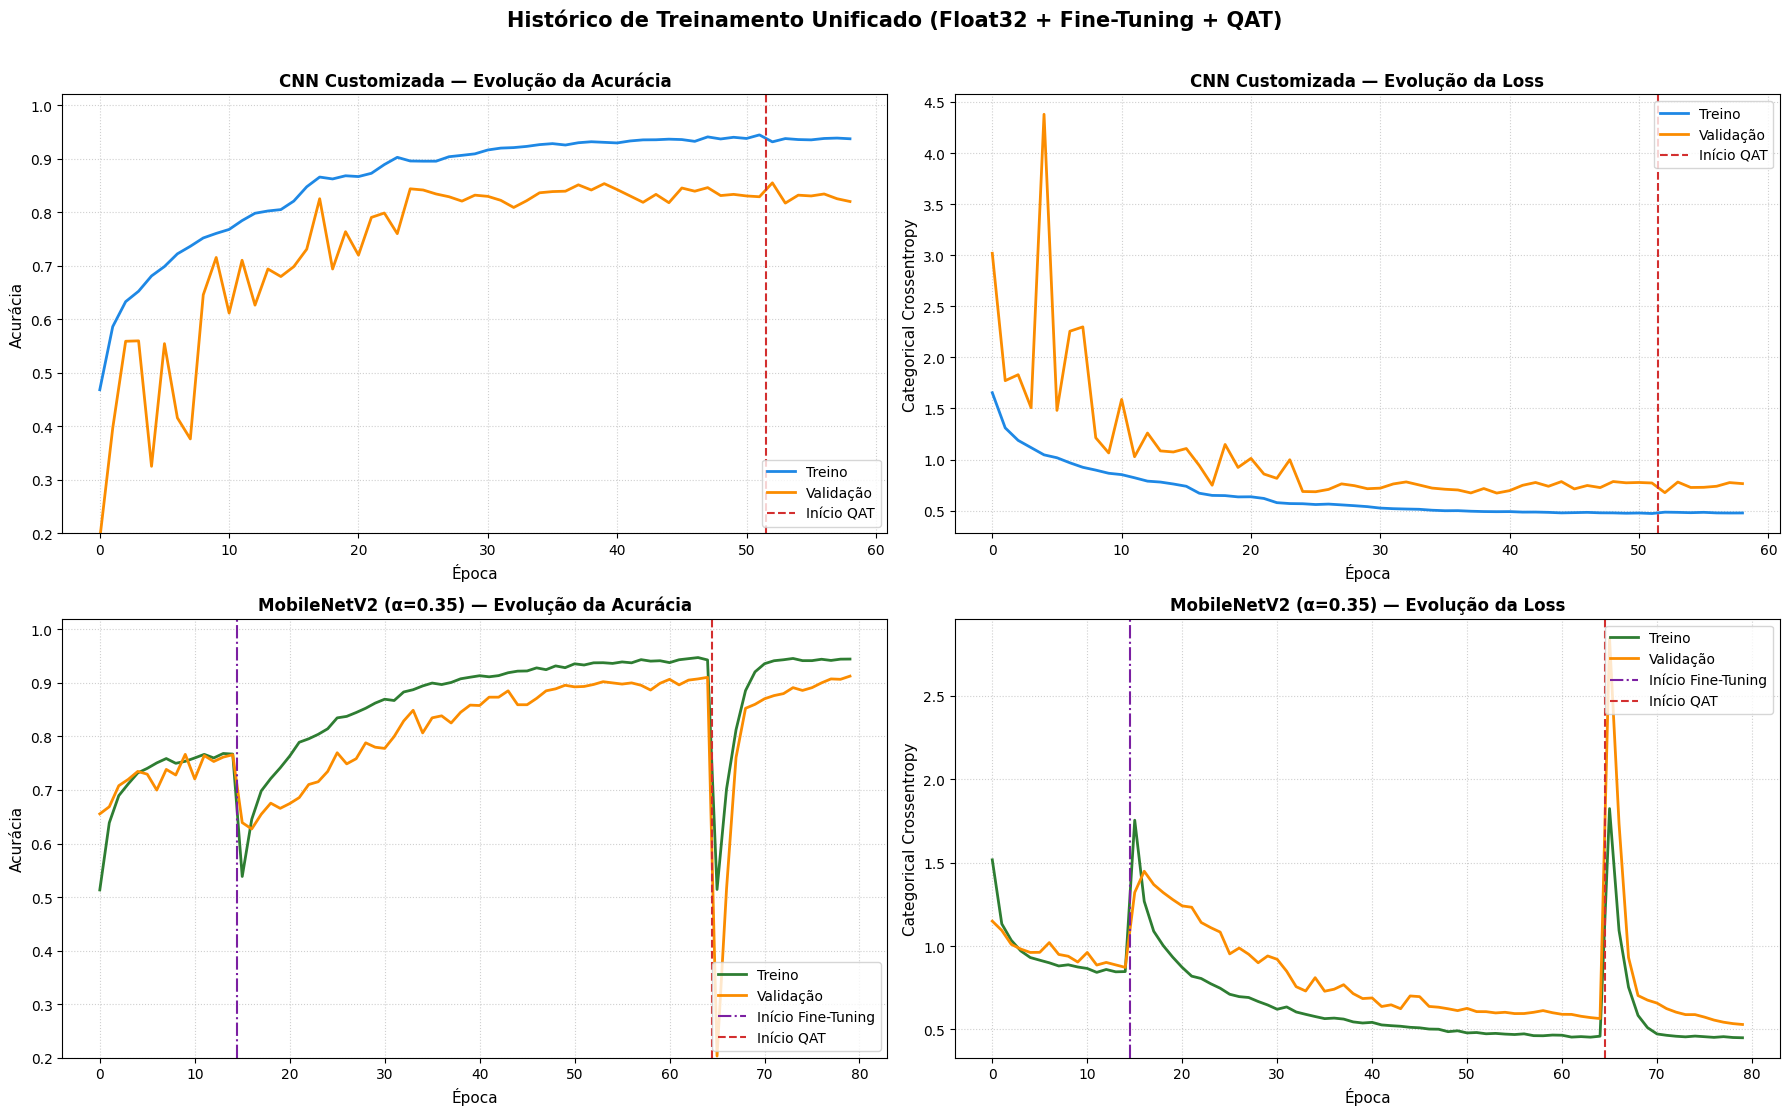

In [ ]:
# --- GRÁFICO 1: Curvas de Aprendizado Padronizadas (Float32 + QAT) ---
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 12, 'axes.labelsize': 11})
fig, axes = plt.subplots(2, 2, figsize=(18, 11))

# Concatena histórico CNN (Float32 + QAT)
acc_tr_cnn = history_cnn.history['accuracy'] + history_cnn_qat.history['accuracy']
acc_val_cnn = history_cnn.history['val_accuracy'] + history_cnn_qat.history['val_accuracy']
loss_tr_cnn = history_cnn.history['loss'] + history_cnn_qat.history['loss']
loss_val_cnn = history_cnn.history['val_loss'] + history_cnn_qat.history['val_loss']
ep_qat_start_cnn = len(history_cnn.history['accuracy'])

# Concatena histórico MobileNetV2 (Fase 1 + Fase 2 + QAT)
acc_tr_mb = history_mbnet_phase1.history['accuracy'] + history_mbnet_phase2.history['accuracy'] + history_mbnet_qat.history['accuracy']
acc_val_mb = history_mbnet_phase1.history['val_accuracy'] + history_mbnet_phase2.history['val_accuracy'] + history_mbnet_qat.history['val_accuracy']
loss_tr_mb = history_mbnet_phase1.history['loss'] + history_mbnet_phase2.history['loss'] + history_mbnet_qat.history['loss']
loss_val_mb = history_mbnet_phase1.history['val_loss'] + history_mbnet_phase2.history['val_loss'] + history_mbnet_qat.history['val_loss']
ep_ft_start_mb = len(history_mbnet_phase1.history['accuracy'])
ep_qat_start_mb = ep_ft_start_mb + len(history_mbnet_phase2.history['accuracy'])

# Plot Acurácia CNN
axes[0, 0].plot(acc_tr_cnn, label='Treino', color='#1e88e5', linewidth=2)
axes[0, 0].plot(acc_val_cnn, label='Validação', color='#fb8c00', linewidth=2)
axes[0, 0].axvline(ep_qat_start_cnn - 0.5, color='#d32f2f', linestyle='--', label='Início QAT')
axes[0, 0].set_title('CNN Customizada — Evolução da Acurácia', fontweight='bold')
axes[0, 0].set_xlabel('Época')
axes[0, 0].set_ylabel('Acurácia')
axes[0, 0].set_ylim(0.2, 1.02)
axes[0, 0].grid(True, linestyle=':', alpha=0.6)
axes[0, 0].legend(loc='lower right')

# Plot Loss CNN
axes[0, 1].plot(loss_tr_cnn, label='Treino', color='#1e88e5', linewidth=2)
axes[0, 1].plot(loss_val_cnn, label='Validação', color='#fb8c00', linewidth=2)
axes[0, 1].axvline(ep_qat_start_cnn - 0.5, color='#d32f2f', linestyle='--', label='Início QAT')
axes[0, 1].set_title('CNN Customizada — Evolução da Loss', fontweight='bold')
axes[0, 1].set_xlabel('Época')
axes[0, 1].set_ylabel('Categorical Crossentropy')
axes[0, 1].grid(True, linestyle=':', alpha=0.6)
axes[0, 1].legend(loc='upper right')

# Plot Acurácia MobileNetV2
axes[1, 0].plot(acc_tr_mb, label='Treino', color='#2e7d32', linewidth=2)
axes[1, 0].plot(acc_val_mb, label='Validação', color='#fb8c00', linewidth=2)
axes[1, 0].axvline(ep_ft_start_mb - 0.5, color='#7b1fa2', linestyle='-.', label='Início Fine-Tuning')
axes[1, 0].axvline(ep_qat_start_mb - 0.5, color='#d32f2f', linestyle='--', label='Início QAT')
axes[1, 0].set_title('MobileNetV2 (α=0.35) — Evolução da Acurácia', fontweight='bold')
axes[1, 0].set_xlabel('Época')
axes[1, 0].set_ylabel('Acurácia')
axes[1, 0].set_ylim(0.2, 1.02)
axes[1, 0].grid(True, linestyle=':', alpha=0.6)
axes[1, 0].legend(loc='lower right')

# Plot Loss MobileNetV2
axes[1, 1].plot(loss_tr_mb, label='Treino', color='#2e7d32', linewidth=2)
axes[1, 1].plot(loss_val_mb, label='Validação', color='#fb8c00', linewidth=2)
axes[1, 1].axvline(ep_ft_start_mb - 0.5, color='#7b1fa2', linestyle='-.', label='Início Fine-Tuning')
axes[1, 1].axvline(ep_qat_start_mb - 0.5, color='#d32f2f', linestyle='--', label='Início QAT')
axes[1, 1].set_title('MobileNetV2 (α=0.35) — Evolução da Loss', fontweight='bold')
axes[1, 1].set_xlabel('Época')
axes[1, 1].set_ylabel('Categorical Crossentropy')
axes[1, 1].grid(True, linestyle=':', alpha=0.6)
axes[1, 1].legend(loc='upper right')

plt.suptitle('Histórico de Treinamento Unificado (Float32 + Fine-Tuning + QAT)', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

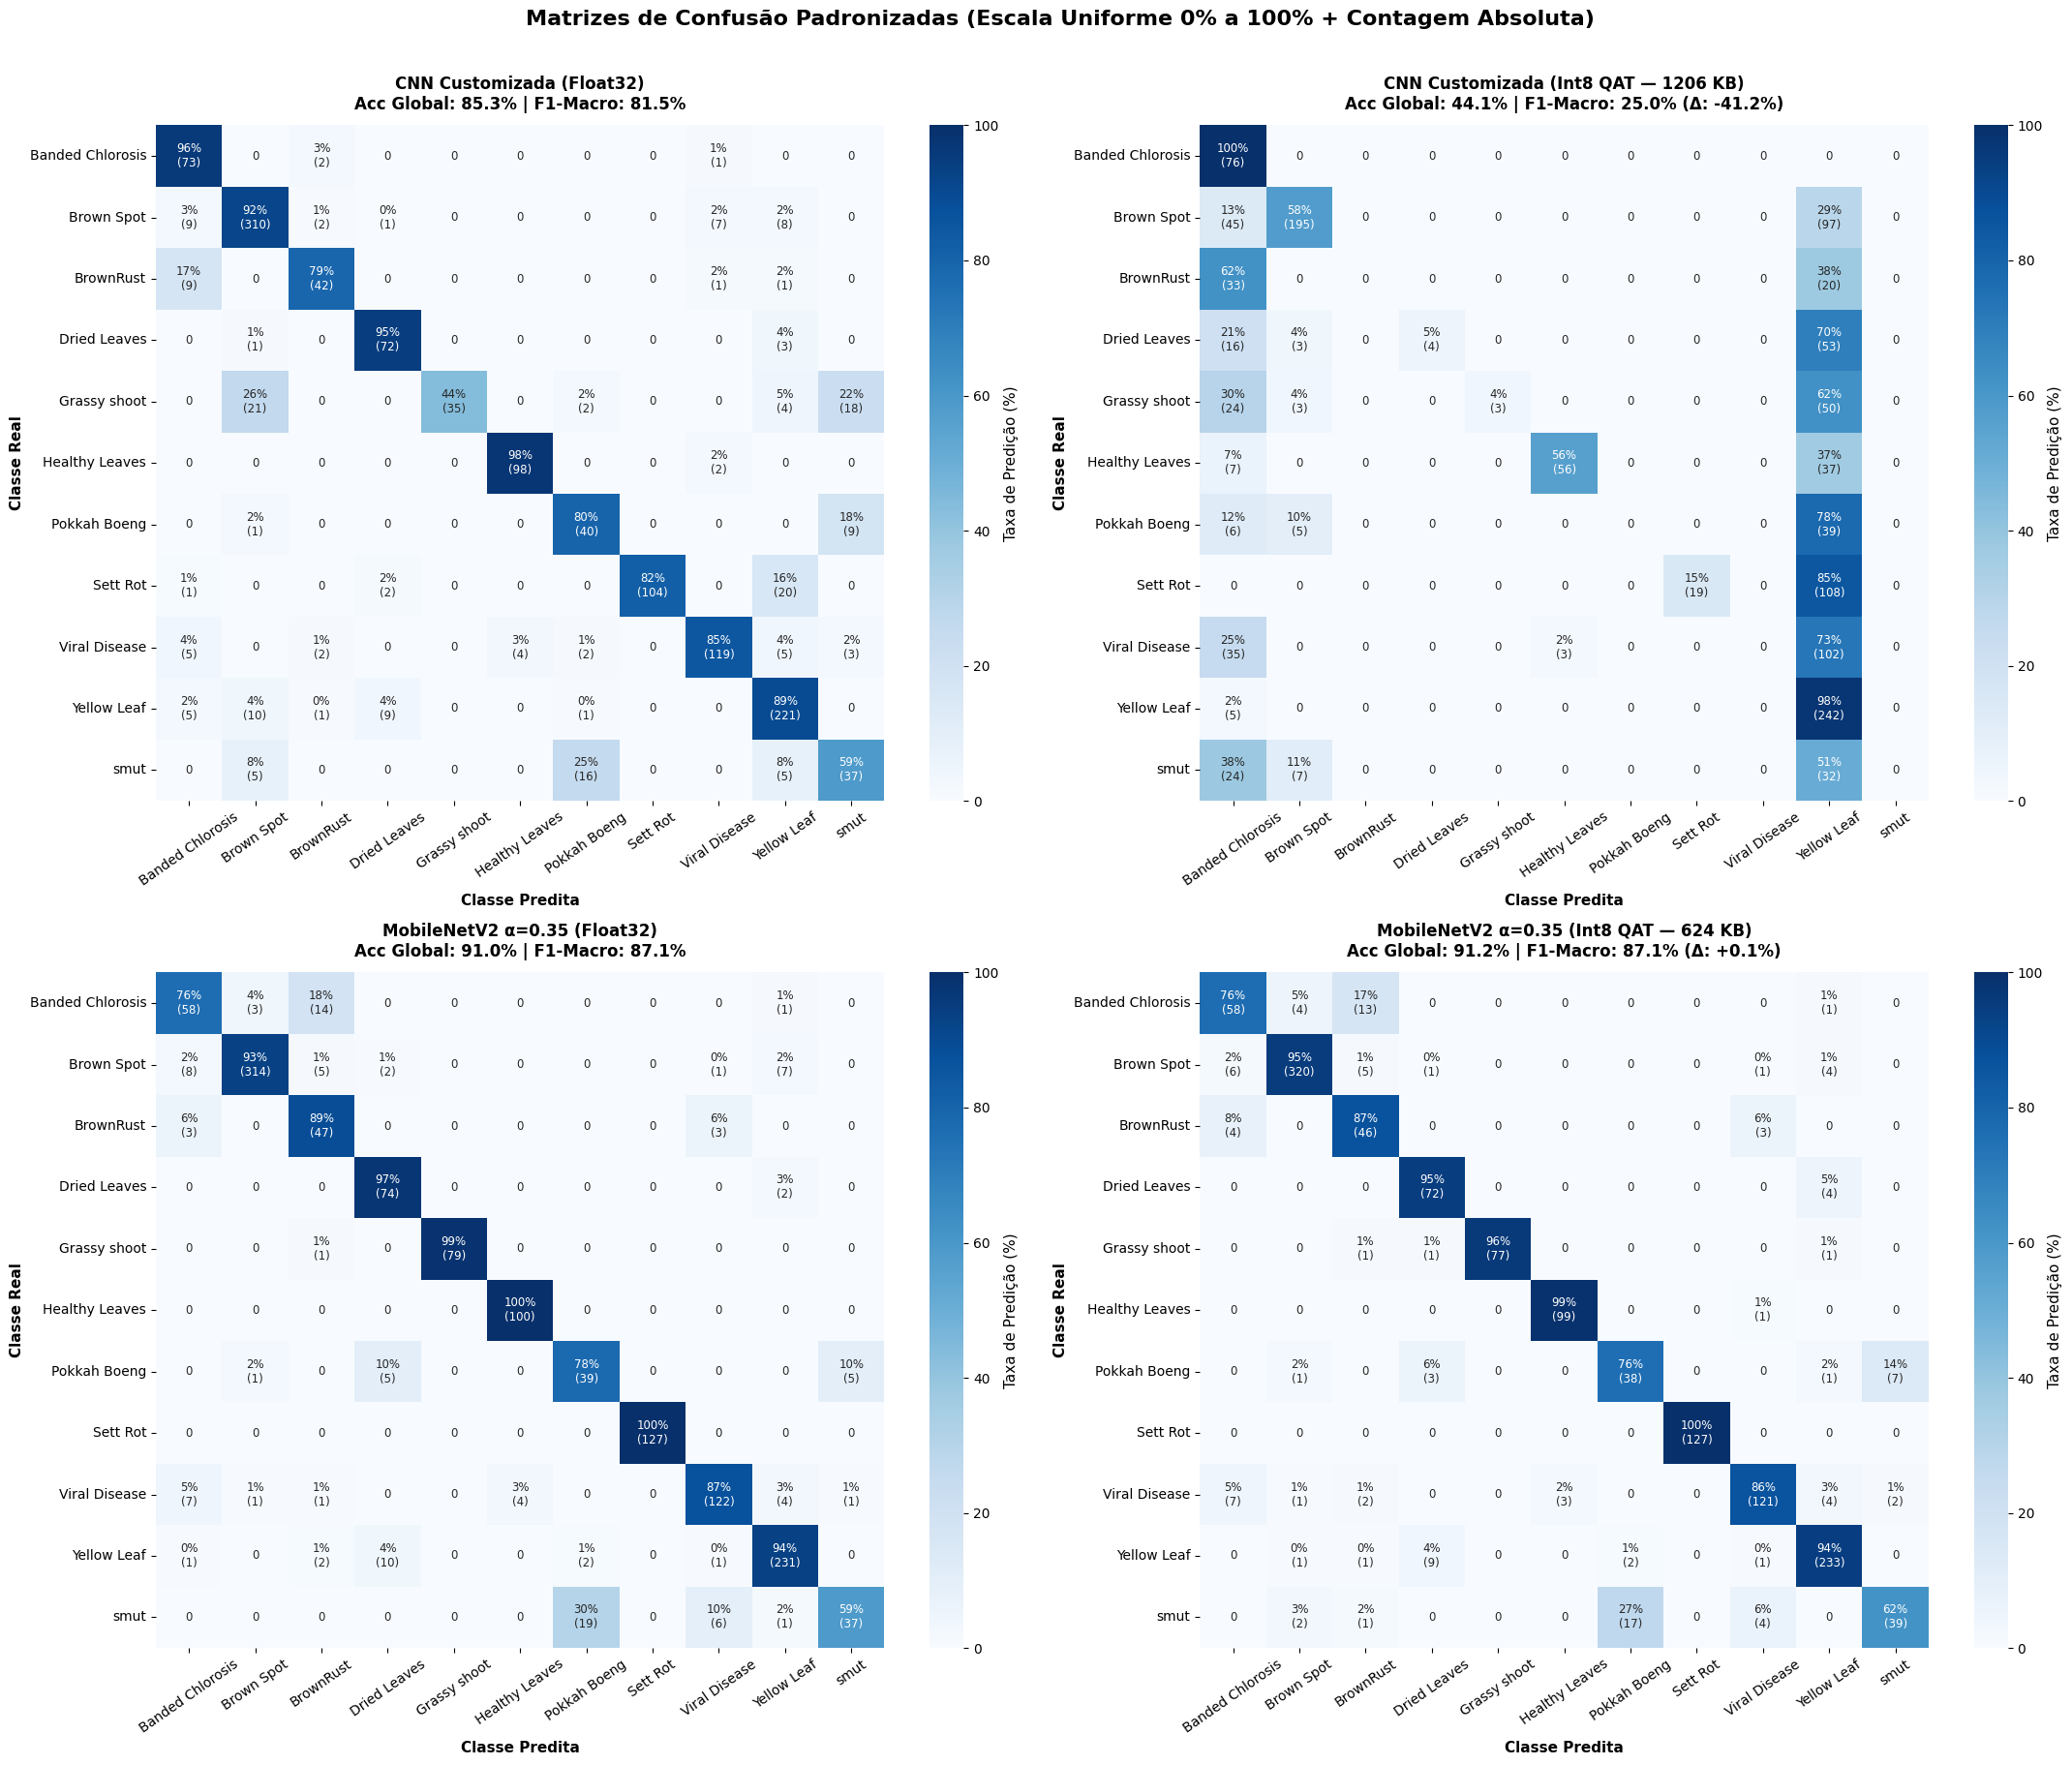

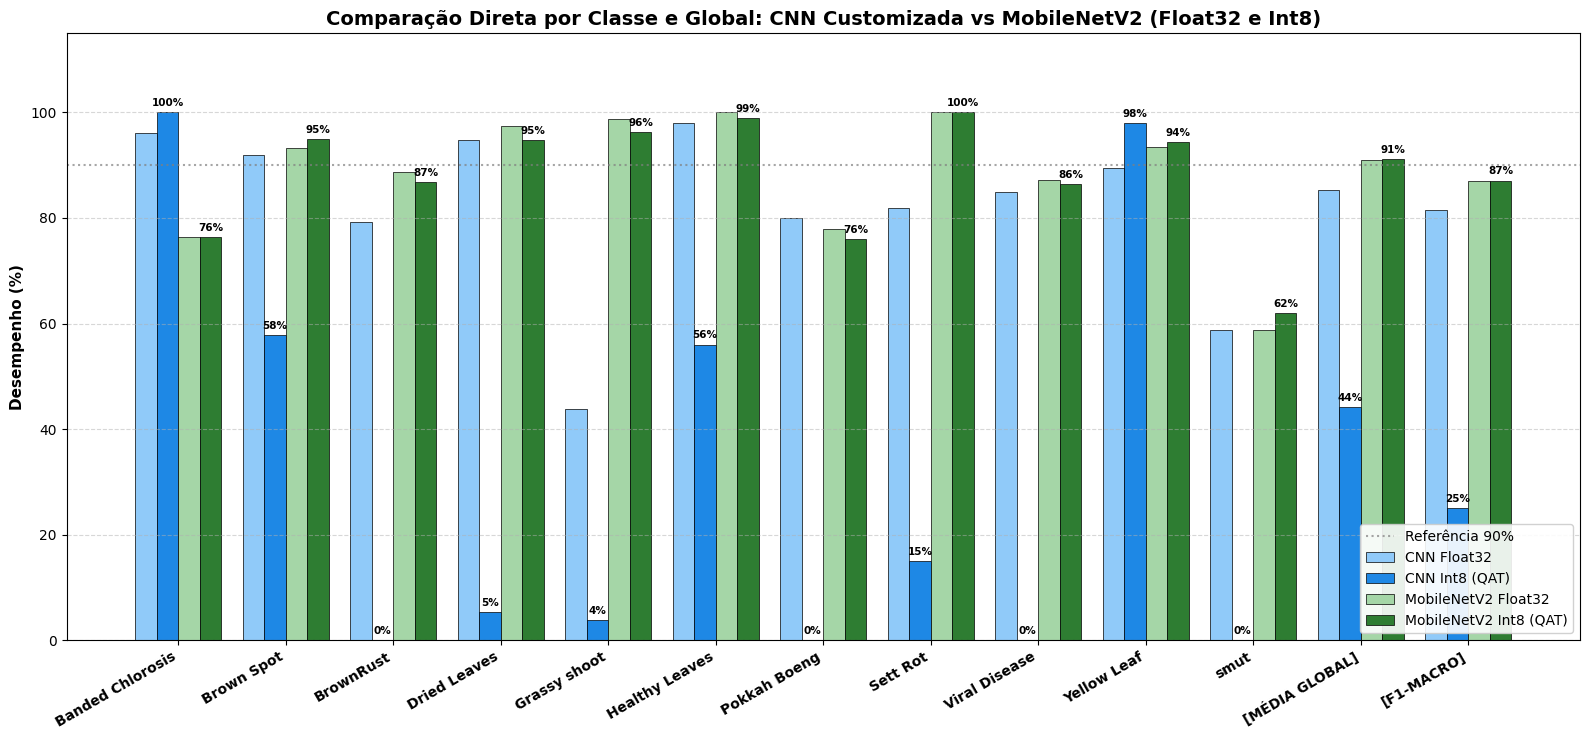

In [ ]:
# --- GRÁFICO 2: Matrizes de Confusão Normalizadas (%) com Escala Uniforme (0 a 100%) ---
fig, axes = plt.subplots(2, 2, figsize=(22, 18))

modelos_cm = [
    (cm_cnn_f32,  f"CNN Customizada (Float32)\nAcc Global: {global_cnn_f32:.1f}% | F1-Macro: {f1_cnn_f32:.1f}%", axes[0, 0]),
    (cm_cnn_int8, f"CNN Customizada (Int8 QAT — {tamanho_cnn_kb:.0f} KB)\nAcc Global: {global_cnn_int8:.1f}% | F1-Macro: {f1_cnn_int8:.1f}% (Δ: {global_cnn_int8 - global_cnn_f32:+.1f}%)", axes[0, 1]),
    (cm_mb_f32,   f"MobileNetV2 α=0.35 (Float32)\nAcc Global: {global_mb_f32:.1f}% | F1-Macro: {f1_mb_f32:.1f}%", axes[1, 0]),
    (cm_mb_int8,  f"MobileNetV2 α=0.35 (Int8 QAT — {tamanho_mbnet_kb:.0f} KB)\nAcc Global: {global_mb_int8:.1f}% | F1-Macro: {f1_mb_int8:.1f}% (Δ: {global_mb_int8 - global_mb_f32:+.1f}%)", axes[1, 1]),
]

for cm, titulo, ax in modelos_cm:
    # Normaliza por linha (% de Recall por classe real) para uniformizar a escala de cores
    cm_perc = (cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]) * 100

    annot_matrix = np.empty(cm.shape, dtype=object)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            val_p = cm_perc[i, j]
            val_c = cm[i, j]
            annot_matrix[i, j] = f"{val_p:.0f}%\n({val_c})" if val_c > 0 else "0"

    sns.heatmap(
        cm_perc, annot=annot_matrix, fmt='', cmap='Blues',
        vmin=0, vmax=100, cbar=True, ax=ax,
        xticklabels=class_names, yticklabels=class_names,
        cbar_kws={'label': 'Taxa de Predição (%)'},
        annot_kws={'size': 8.5}
    )
    ax.set_title(titulo, fontweight='bold', pad=12)
    ax.set_xlabel('Classe Predita', fontweight='bold')
    ax.set_ylabel('Classe Real', fontweight='bold')
    ax.tick_params(axis='x', rotation=35)
    ax.tick_params(axis='y', rotation=0)

plt.suptitle('Matrizes de Confusão Padronizadas (Escala Uniforme 0% a 100% + Contagem Absoluta)', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# --- GRÁFICO 3: Comparativo de Barras Agrupadas por Classe e Global ---
fig, ax = plt.subplots(figsize=(16, 7.5))

labels_eixo = class_names + ['[MÉDIA GLOBAL]', '[F1-MACRO]']
v_cnn_f32 = np.concatenate([acc_cnn_f32, [global_cnn_f32, f1_cnn_f32]])
v_cnn_i8  = np.concatenate([acc_cnn_int8, [global_cnn_int8, f1_cnn_int8]])
v_mb_f32  = np.concatenate([acc_mb_f32,  [global_mb_f32, f1_mb_f32]])
v_mb_i8   = np.concatenate([acc_mb_int8, [global_mb_int8, f1_mb_int8]])

x = np.arange(len(labels_eixo))
largura = 0.20

b1 = ax.bar(x - 1.5*largura, v_cnn_f32, largura, label='CNN Float32', color='#90caf9', edgecolor='black', linewidth=0.5)
b2 = ax.bar(x - 0.5*largura, v_cnn_i8,  largura, label='CNN Int8 (QAT)', color='#1e88e5', edgecolor='black', linewidth=0.5)
b3 = ax.bar(x + 0.5*largura, v_mb_f32,  largura, label='MobileNetV2 Float32', color='#a5d6a7', edgecolor='black', linewidth=0.5)
b4 = ax.bar(x + 1.5*largura, v_mb_i8,   largura, label='MobileNetV2 Int8 (QAT)', color='#2e7d32', edgecolor='black', linewidth=0.5)

ax.set_ylabel('Desempenho (%)', fontweight='bold')
ax.set_title('Comparação Direta por Classe e Global: CNN Customizada vs MobileNetV2 (Float32 e Int8)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(labels_eixo, rotation=30, ha='right', fontweight='bold')
ax.set_ylim(0, 115)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.axhline(90, color='gray', linestyle=':', alpha=0.7, label='Referência 90%')
ax.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)

for bar in [b2, b4]:
    for rect in bar:
        h = rect.get_height()
        ax.annotate(f'{h:.0f}%', xy=(rect.get_x() + rect.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=7.5, fontweight='bold')

plt.tight_layout()
plt.show()

---
# 6. Exportação Automatizada para ESP32-S3 (`.h` com Metadados e Alinhamento SIMD)

Gera o arquivo de cabeçalho C/C++ já com a diretiva `alignas(16)` (exigida pelo coprocessador vetorial PIE do ESP32-S3 na biblioteca `esp-nn`), além das macros de `scale`, `zero_point` e nomes das classes prontos para uso no ESP-IDF / Arduino.

In [ ]:
# Seleciona automaticamente o modelo Int8 vencedor (ou defina manualmente)
MODEL_ESCOLHIDO = "model_mbnet_int8.tflite" if global_mb_int8 >= (global_cnn_int8 - 1.5) else "model_cnn_int8.tflite"
NOME_SAIDA = "model_cane_disease"

# Extrai os parâmetros reais de quantização do arquivo TFLite escolhido
interp = tf.lite.Interpreter(model_path=MODEL_ESCOLHIDO)
interp.allocate_tensors()
in_det = interp.get_input_details()[0]
out_det = interp.get_output_details()[0]

in_scale, in_zp = in_det['quantization']
out_scale, out_zp = out_det['quantization']

!xxd -i {MODEL_ESCOLHIDO} > {NOME_SAIDA}_raw.h

with open(f"{NOME_SAIDA}_raw.h", "r") as f_in:
    conteudo_hex = f_in.read()

classes_c_array = ",\n    ".join([f'"{c}"' for c in class_names])

header_completo = f"""#ifndef MODEL_CANE_DISEASE_H
#define MODEL_CANE_DISEASE_H

#include <stdint.h>

// ============================================================================
// Modelo TFLite Int8 Gerado Automaticamente para ESP32-S3 (TFLite Micro + esp-nn)
// Arquivo fonte: {MODEL_ESCOLHIDO}
// ============================================================================

#define MODEL_INPUT_WIDTH       {IMG_SHAPE[1]}
#define MODEL_INPUT_HEIGHT      {IMG_SHAPE[0]}
#define MODEL_INPUT_CHANNELS    {IMG_SHAPE[2]}
#define MODEL_NUM_CLASSES       {NUM_CLASSES}

#define MODEL_INPUT_SCALE       {in_scale:.8f}f
#define MODEL_INPUT_ZERO_POINT  {in_zp}
#define MODEL_OUTPUT_SCALE      {out_scale:.8f}f
#define MODEL_OUTPUT_ZERO_POINT {out_zp}

static const char* kCategoryLabels[MODEL_NUM_CLASSES] = {{
    {classes_c_array}
}};

// Conversão direta de pixel RGB888 (uint8_t [0..255]) para Int8 [-128..127] sem float:
static inline int8_t quantize_pixel_u8_to_i8(uint8_t pixel_u8) {{
    return (int8_t)((int32_t)pixel_u8 - 128);
}}

alignas(16) {conteudo_hex}

#endif // MODEL_CANE_DISEASE_H
"""

with open(f"{NOME_SAIDA}.h", "w") as f_out:
    f_out.write(header_completo)

print(f"\n✅ Arquivo {NOME_SAIDA}.h gerado com sucesso a partir de '{MODEL_ESCOLHIDO}'!")
print(f"   - Tamanho do modelo  : {os.path.getsize(MODEL_ESCOLHIDO)/1024:.2f} KB")
print(f"   - Input Quantization : scale = {in_scale:.8f}, zero_point = {in_zp}")
print(f"   - Output Quantization: scale = {out_scale:.8f}, zero_point = {out_zp}")
print(f"   - Total de Classes   : {NUM_CLASSES}")

/bin/bash: line 1: xxd: command not found

✅ Arquivo model_cane_disease.h gerado com sucesso a partir de 'model_mbnet_int8.tflite'!
   - Tamanho do modelo  : 624.29 KB
   - Input Quantization : scale = 0.00784314, zero_point = 0
   - Output Quantization: scale = 0.00390625, zero_point = -128
   - Total de Classes   : 11


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
# Download dos arquivos gerados
from google.colab import files

files.download("model_cnn_int8.tflite")
files.download("model_mbnet_int8.tflite")
files.download(f"{NOME_SAIDA}.h")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>